# Figure 6 (networks): slingshot therapy across the SN5.2 RPA networks

`figure6.ipynb` shows the slingshot on the FCD-IFFL: adapt the system to the
*opposite* of the treatment first, then switch, and the same treatment produces
a larger response. This notebook asks whether that is a property of one circuit
or of RPA itself, using the six small networks of Araujo & Liotta (2018, Fig. 8),
cases a–f. They combine opposer and balancer modules into 5–7 node networks;
none of them has a biological interpretation, so they serve as a test bed.

For every network the **RPA parameters**, those that leave the output's steady
state $O^*$ unchanged ($\partial O^*/\partial p = 0$), are found symbolically
from the analytic steady state (`rpa_control.models.RPAModel`). Each one is then
given the same treatment, a step $p \to 2p_0$, in two runs that both start at
the baseline steady state:

* **control**: $p$ held at $p_0$ until the treatment;
* **slingshot**: first a preparation phase, in which $p$ is slowly ramped to
  $p_0/2$ (the opposite direction) and held there until the network has
  adapted, then the same treatment.

The readout is the **amplification** $\max_t|O_\text{sling}-O^*| \,/\,
\max_t|O_\text{ctrl}-O^*|$. It ignores the sign of the response on purpose: in
networks without biological meaning there is no "right" direction for $O$, and
the claim is only that the response is amplified.

* **Panel B**: one example trace (case b, $k_7$).
* **Panel C**: the amplification for every RPA parameter of every network.
* **SI**: all traces.

In [9]:
"""Figure 6 (networks): shared imports, style and constants."""
import copy
import sys

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy.integrate import solve_ivp
from IPython.display import display

sys.path.insert(0, '../src')
from rpa_control.models import ALL_MODELS
from rpa_control.simulation import eval_ss
from rpa_control.style import set_style
from rpa_control.paths import PLOTS_DIR, save_fig

set_style()

FOLD   = 2.0     # treatment p -> FOLD*p0;  slingshot preparation p -> p0/FOLD
T_RAMP = 30.0    # preparation: linear ramp p0 -> p0/FOLD ...
T_HOLD = 60.0    # ... then hold until adapted (asserted below)
T_PREP = T_RAMP + T_HOLD    # treatment starts at t = 0, preparation at t = -T_PREP
T_END  = 100.0   # long enough for O to return to O* in every network (asserted below)
DT     = 0.02

CTRL_STYLE  = dict(color='tomato', ls='--', lw=1.5, label='control')
SLING_STYLE = dict(color='steelblue', ls='-', lw=1.5, label='slingshot')


def clean_ax(ax):
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)

## Models

The equations and parameter values are those of `rpa_control.models` (taken
from the paper, with the sign typo in case a's $\dot B$ fixed). Three networks
need different base values here, because with the paper's values some steady
states are negative or zero, or the network loses stability when an RPA parameter
is doubled:

| case | paper | here | why |
|---|---|---|---|
| c | Input = 1 | Input = 2 | $O_2^* < 0$ at $\div 2$ / $\times 2$ of several RPA parameters |
| d | Input = 1, $k_2$ = 0.5 | Input = 4, $k_2$ = 1 | $O_1^* = 0$ at $\div 2$ / $\times 2$; unstable at $2k_3$, $2k_4$, $k_2/2$, $k_5/2$ |
| f | Input = 1 | Input = 3 | $O_2^* = 0$, $O_3^* < 0$ already at baseline |

$O^*$ does not depend on any of these, and the set of RPA parameters is unchanged.
With them, every steady state used below is positive and every run returns to
$O^*$ (both are asserted in `slingshot_pair`).

Input enters every network only as the product $k_1\cdot\text{Input}$, so it is
an RPA parameter wherever $k_1$ is and gives identical results. It is left
out of the bars, and $k_1$ stands for both.

In [10]:
# --- Models: base values adjusted for c, d, f (see table above) -------------
# A shallow copy with a new params_base is enough: the symbolic steady state,
# the RPA-parameter list and the lambdified RHS do not depend on base values.
RETUNE = {'c': dict(Input=2.0),
          'd': dict(Input=4.0, k2=1.0),
          'f': dict(Input=3.0)}
SKIP = {'Input'}    # identical to k1 in every network


def retuned(model):
    if model.name not in RETUNE:
        return model
    m = copy.copy(model)
    m.params_base = {**model.params_base, **RETUNE[model.name]}
    return m


def is_linear(model):
    """True if every RHS is affine in the state (all second derivatives vanish)."""
    n = len(model.state_vars) - len(model._extra_vars)
    xs = model._sym_state[:n]
    return all(sp.hessian(eq, xs).is_zero_matrix for eq in model._equations)


MODELS = [retuned(m) for m in ALL_MODELS]
for m in MODELS:
    display(m)
    print(f"  O* = {eval_ss(m)[m.output_idx]:.3f}   "
          f"{'linear' if is_linear(m) else 'nonlinear'}   "
          f"perturbed: {[p for p in m.rpa_params if p not in SKIP]}")

RPAModel('a', output='O', rpa_params=['Input', 'k1', 'k2', 'k3'])

  O* = 0.750   nonlinear   perturbed: ['k1', 'k2', 'k3']


RPAModel('b', output='O', rpa_params=['Input', 'k1', 'k2', 'k5', 'k7'])

  O* = 0.500   nonlinear   perturbed: ['k1', 'k2', 'k5', 'k7']


RPAModel('c', output='O', rpa_params=['Input', 'k1', 'k2', 'k3', 'k9', 'k10', 'k11'])

...

  O* = 0.500   linear   perturbed: ['k1', 'k2', 'k3', 'k4', 'k5', 'k8', 'k9', 'k10']


RPAModel('e', output='O', rpa_params=['Input', 'k1', 'k2', 'k6', 'k7', 'k8'])

  O* = 0.500   nonlinear   perturbed: ['k1', 'k2', 'k6', 'k7', 'k8']


RPAModel('f', output='O', rpa_params=['Input', 'k1', 'k2', 'k3', 'k6', 'k7', 'k8', 'k11', 'k12', 'k13'])

  O* = 0.500   linear   perturbed: ['k1', 'k2', 'k3', 'k6', 'k7', 'k8', 'k11', 'k12', 'k13']


## Slingshot vs. control

Both runs start at the baseline steady state at $t = -T_\text{prep}$:

* **control**: $p = p_0$ until $t = 0$;
* **slingshot**: preparation, a linear ramp $p_0 \to p_0/2$ over `T_RAMP`, then
  a hold at $p_0/2$ for `T_HOLD`. This is long enough for every network to
  adapt: all states reach the steady state for $p_0/2$, and $O$ is back at $O^*$
  (asserted in `slingshot_pair`).

At $t = 0$ both switch to $2p_0$. Because the preparation ends at the adapted
state, the amplification depends only on where it ends, not on how it got
there; a shorter hold would change it. The ramp keeps the preparation's own
transient in $O$ small. An abrupt step to $p_0/2$ would itself be a
perturbation, in the opposite direction to the treatment.

Only the network's own states are integrated; the Cancer readout that
`rpa_control.models` attaches to every model is dropped.

In [11]:
# --- Core helper: control vs slingshot, preparation + treatment -------------
def rhs(model, param, p_of_t):
    """RHS of the network's states, with param following p_of_t(t), all others at base."""
    names = model._param_names
    i = names.index(param)
    base = [model.params_base[k] for k in names]

    def f(t, y):
        pv = list(base)
        pv[i] = p_of_t(t)
        return model._f_lam(*y, *pv)
    return f


def slingshot_pair(model, param, fold=FOLD, T=T_END, dt=DT):
    """Control and slingshot runs for one RPA parameter, on t in [-T_PREP, T].

    Both start at the baseline steady state at t = -T_PREP. The control holds p0
    until t = 0; the slingshot ramps p0 -> p0/fold over T_RAMP and holds for
    T_HOLD. At t = 0 both switch to fold*p0. Returns t, y_ctrl, y_sling,
    p_ctrl, p_sling and O*.

    Asserts that param is RPA (same O* at p0/fold, p0, fold*p0), that those
    three steady states are positive, that the slingshot has adapted to p0/fold
    by t = 0, and that both runs return to O* by T.
    """
    p0 = model.params_base[param]
    oi = model.output_idx
    n = len(model.state_vars) - len(model._extra_vars)    # drop the Cancer readout
    ss_base, ss_prep, ss_treat = (eval_ss(model, {param: v})[:n]
                                  for v in (p0, p0 / fold, p0 * fold))
    O_star = ss_base[oi]

    tag = f'case {model.name}, {param}'
    assert np.allclose([ss_prep[oi], ss_treat[oi]], O_star, rtol=1e-9), f'{tag}: O* moves'
    assert all((s > 0).all() for s in (ss_base, ss_prep, ss_treat)), \
        f'{tag}: non-positive steady state'

    def p_ctrl(t):
        return p0 if t < 0 else fold * p0

    def p_sling(t):
        if t >= 0:
            return fold * p0
        return p0 + (p0 / fold - p0) * min((t + T_PREP) / T_RAMP, 1.0)

    kw = dict(method='Radau', rtol=1e-8, atol=1e-10)
    t_prep = np.linspace(-T_PREP, 0, int(round(T_PREP / dt)) + 1)
    t_treat = np.linspace(0, T, int(round(T / dt)) + 1)

    # preparation: the control sits at its steady state, the slingshot ramps and holds
    y_s_prep = solve_ivp(rhs(model, param, p_sling), (-T_PREP, 0), ss_base,
                         t_eval=t_prep, **kw).y
    y_c_prep = np.tile(ss_base[:, None], (1, len(t_prep)))
    adapt_err = np.abs(y_s_prep[:, -1] - ss_prep).max() / np.abs(ss_prep).max()
    assert adapt_err < 1e-3, f'{tag}: not adapted to p0/{fold:g} by t=0 ({adapt_err:.1e})'

    # treatment: both switch to fold*p0 at t = 0
    f_treat = rhs(model, param, lambda t: fold * p0)
    y_c_treat = solve_ivp(f_treat, (0, T), y_c_prep[:, -1], t_eval=t_treat, **kw).y
    y_s_treat = solve_ivp(f_treat, (0, T), y_s_prep[:, -1], t_eval=t_treat, **kw).y
    end_dev = max(abs(y_c_treat[oi, -1] - O_star), abs(y_s_treat[oi, -1] - O_star))
    assert end_dev < 1e-4 * O_star, f'{tag}: O has not returned to O* by t={T}'

    t = np.concatenate([t_prep[:-1], t_treat])
    y_ctrl = np.concatenate([y_c_prep[:, :-1], y_c_treat], axis=1)
    y_sling = np.concatenate([y_s_prep[:, :-1], y_s_treat], axis=1)
    return (t, y_ctrl, y_sling, np.array([p_ctrl(ti) for ti in t]),
            np.array([p_sling(ti) for ti in t]), O_star)


def settle_time(t, dev, frac=0.01):
    """Last time |O - O*| exceeds frac x its peak."""
    return t[np.nonzero(dev > frac * dev.max())[0][-1]]

## All networks, all RPA parameters

The peak ratio (over the treatment phase, $t \ge 0$) is the figure's readout.
The summary table also lists the ratio of the integrated deviations
$\int_0^T|O-O^*|\,dt$; the preparation's own peak deviation of $O$, as a
fraction of the control's treatment peak (the cost of preparing); and the
lowest value $O$, and any state, reaches in either run. The integrator nodes
of these networks have zero-order terms (e.g. $\dot O_1 = k_7 I - k_8$), so
nothing keeps the state positive during a transient: the larger slingshot
excursions can take $O$, or a hidden node, below zero. All steady states are
positive.

For the **linear** networks (c, d, f) the amplification is set by linearity
rather than by topology. After the step, $O(t)-O^*$ is proportional to how far
the starting state lies from the treated steady state. If the adapted state depends
on $p$ as $a+b\,p$, the slingshot starts $(f-1/f)/(f-1) = (f+1)/f = 1.5\times$
as far away; if it depends on $p$ as $a+b/p$, $(f-1/f)/(1-1/f) = f+1 = 3\times$. Only the
nonlinear networks (a, b, e) give values in between.

In [12]:
# --- Run every (network, RPA parameter) pair --------------------------------
results = {}
print(f"{'case':4s} {'param':5s}  {'peak ratio':>10s}  {'AUC ratio':>9s}  {'prep/ctrl':>9s}  "
      f"{'min O':>7s}  {'min state':>9s}  {'O*':>5s}")
for m in MODELS:
    oi = m.output_idx
    results[m.name] = {}
    for p in m.rpa_params:
        if p in SKIP:
            continue
        t, y_c, y_s, p_c, p_s, O_star = slingshot_pair(m, p)
        dev_c, dev_s = np.abs(y_c[oi] - O_star), np.abs(y_s[oi] - O_star)
        post = t >= 0
        r = dict(t=t, O_ctrl=y_c[oi], O_sling=y_s[oi], O_star=O_star,
                 A_peak=dev_s[post].max() / dev_c[post].max(),
                 A_auc=(np.trapezoid(dev_s[post], t[post])
                        / np.trapezoid(dev_c[post], t[post])),
                 prep=dev_s[~post].max() / dev_c[post].max(),
                 O_min=min(y_c[oi].min(), y_s[oi].min()),
                 x_min=min(y_c.min(), y_s.min()),
                 t_settle=max(settle_time(t[post], dev_c[post]),
                              settle_time(t[post], dev_s[post])))
        results[m.name][p] = r
        print(f"{m.name:4s} {p:5s}  {r['A_peak']:10.2f}  {r['A_auc']:9.2f}  {r['prep']:9.2f}  "
              f"{r['O_min']:7.2f}  {r['x_min']:9.2f}  {O_star:5.2f}")

A_all = [r['A_peak'] for res in results.values() for r in res.values()]
print(f"\n{len(A_all)} RPA parameters, amplification {min(A_all):.2f}-{max(A_all):.2f}, "
      f"all > 1: {all(a > 1 for a in A_all)}")

case param  peak ratio  AUC ratio  prep/ctrl    min O  min state     O*
a    k1           1.55       1.56       0.15     0.70       0.03   0.75
a    k2           1.48       1.46       0.10     0.65       0.30   0.75
a    k3           2.94       2.61       0.31     0.28      -0.74   0.75
b    k1           1.99       1.59       0.13     0.47       0.47   0.50
b    k2           1.93       2.62       0.38     0.21       0.21   0.50
b    k5           1.92       1.54       0.08     0.48       0.48   0.50
b    k7           1.96       3.00       0.32     0.20       0.16   0.50
c    k1           1.50       1.50       0.06     0.19      -0.58   0.50
c    k2           1.50       1.50       0.07     0.39       0.30   0.50
c    k3           3.00       3.00       0.26    -0.65      -2.39   0.50
c    k9           1.50       1.50       0.06     0.36       0.14   0.50
c    k10          1.50       1.50       0.08     0.40       0.26   0.50
c    k11          3.00       3.00       0.20     0.00      -0.83

## Panel B: one example

Case b, $k_7$, treatment phase only. Both runs are at $O^*$ when the treatment
starts, so the output alone cannot tell them apart; the slingshot run has been
prepared at $k_7/2$ (bottom row, before $t = 0$), the control has not. The same
step to $2k_7$ then moves $O$ twice as far. The preparation phase is shown in
the SI traces. This example keeps every state positive throughout; see the
summary table above for the runs that do not.

Figure saved to /home/amir/RL/autodiff-control/plots/figure6_rpa_example.pdf


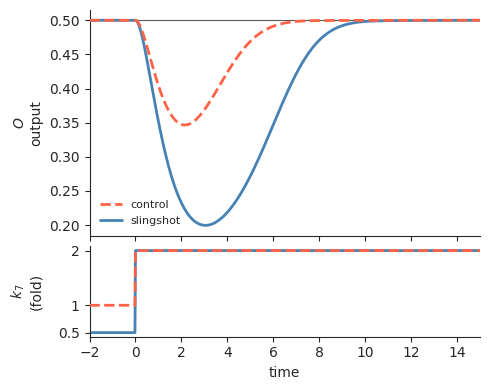

case b, k7: amplification 1.96x


In [17]:
# --- Panel B: example trace, treatment phase ---------------------------------
EX_MODEL, EX_PARAM = 'b', 'k7'
T_LEAD, T_SHOW = 2.0, 15.0     # shown before / after the switch at t = 0

m = next(m for m in MODELS if m.name == EX_MODEL)
t, y_c, y_s, p_ctrl, p_sling, O_star = slingshot_pair(m, EX_PARAM)
p0 = m.params_base[EX_PARAM]
mask = (t >= -T_LEAD) & (t <= T_SHOW)

rows = [('$O$\noutput', y_c[m.output_idx], y_s[m.output_idx]),
        (f'${EX_PARAM[0]}_{EX_PARAM[1:]}$\n(fold)', p_ctrl / p0, p_sling / p0)]

fig, axes = plt.subplots(2, 1, figsize=(5, 4), sharex=True,
                         gridspec_kw={'height_ratios': [2, 0.8]})
for ax, (label, v_c, v_s) in zip(axes, rows):
    ax.plot(t[mask], v_c[mask], **{**CTRL_STYLE, 'lw': 2, 'zorder': 10})
    ax.plot(t[mask], v_s[mask], **{**SLING_STYLE, 'lw': 2})
    ax.set_ylabel(label)
    clean_ax(ax)
axes[0].axhline(O_star, color='0.35', lw=0.8, zorder=0)
axes[0].legend(frameon=False, fontsize=8, loc='lower left')
axes[-1].set_xlim(-T_LEAD, T_SHOW)
axes[-1].set_xlabel('time')
axes[-1].set_yticks([1 / FOLD, 1, FOLD])
axes[-1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v:g}'))
fig.align_ylabels(axes)
plt.tight_layout(h_pad=0.3)
save_fig(fig, 'figure6_rpa_example')
plt.show()

r = results[EX_MODEL][EX_PARAM]
print(f"case {EX_MODEL}, {EX_PARAM}: amplification {r['A_peak']:.2f}x")

## Panel C: amplification in every network

One bar per RPA parameter (log axis, bars start at 1 = no amplification).
Dotted lines mark the two values linearity predicts, $1.5\times$ and $3\times$
(see above). Every parameter in every network is amplified.

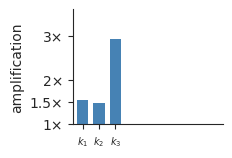

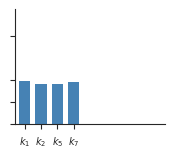

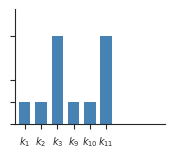

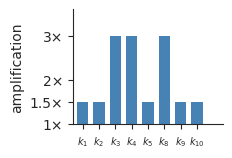

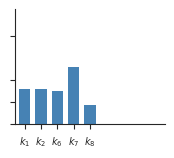

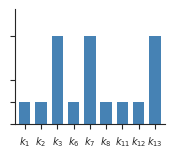

In [19]:
# --- Panel C: amplification bars, one figure per network --------------------
A_TICKS = [1, 1.5, 2, 3]
Y_LABELED = {'a', 'd'}                  # left column of the assembled 2x3 panel

# fixed axes box (inches) so the six figures line up when assembled; saved
# untrimmed (save_fig crops each figure to its content, which would differ)
FIG_W, FIG_H = 2.6, 1.7
AX_LEFT, AX_BOTTOM, AX_W, AX_H = 0.95, 0.3, 1.5, 1.15

n_max = max(len(res) for res in results.values())    # equal bar widths across figures
for m in MODELS:
    params = list(results[m.name])
    A = np.array([results[m.name][p]['A_peak'] for p in params])
    x = np.arange(len(params))
    fig = plt.figure(figsize=(FIG_W, FIG_H))
    ax = fig.add_axes([AX_LEFT / FIG_W, AX_BOTTOM / FIG_H, AX_W / FIG_W, AX_H / FIG_H])
    ax.bar(x, A - 1, bottom=1, width=0.7, color='steelblue', edgecolor='none', linewidth=0.8)
    # for level in (1 + 1 / FOLD, 1 + FOLD):
    #     ax.axhline(level, color='0.6', ls=':', lw=0.8, zorder=0)
    # ax.set_yscale('log', base=2)
    ax.set_ylim(1, 3.6)
    ax.set_yticks(A_TICKS)
    ax.yaxis.set_minor_locator(mtick.NullLocator())
    if m.name in Y_LABELED:
        ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v:g}×'))
        ax.set_ylabel('amplification')
    else:
        ax.tick_params(labelleft=False)
    ax.set_xticks(x)
    ax.set_xticklabels([f'$k_{{{p[1:]}}}$' for p in params], fontsize=7)
    ax.set_xlim(-0.6, n_max - 0.4)
    # ax.set_title(f"case {m.name}" + (' (linear)' if is_linear(m) else ''), fontsize=8)
    clean_ax(ax)
    fig.savefig(PLOTS_DIR / f'figure6_rpa_amplification_{m.name}.pdf')
    plt.show()

## SI: all traces

$O(t)$ for every RPA parameter, control vs. slingshot, one figure per network:
the preparation ($-T_\text{prep} \le t < 0$, slingshot only) and the treatment
($t \ge 0$, dotted line). Each figure's time axis runs until the slowest of its
treatment responses has settled to 1% of its peak deviation.

Figure saved to /home/amir/RL/autodiff-control/plots/SI_figure6_rpa_traces_a.pdf


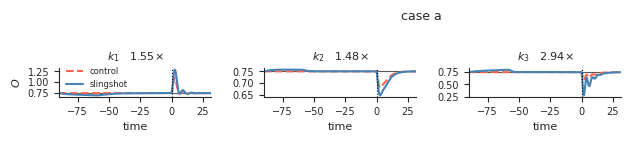

Figure saved to /home/amir/RL/autodiff-control/plots/SI_figure6_rpa_traces_b.pdf


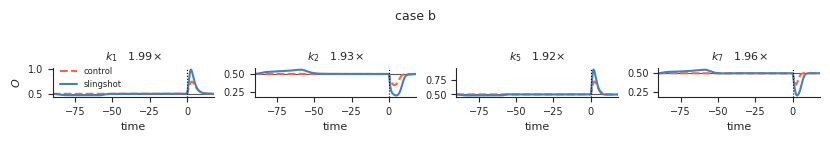

Figure saved to /home/amir/RL/autodiff-control/plots/SI_figure6_rpa_traces_c.pdf


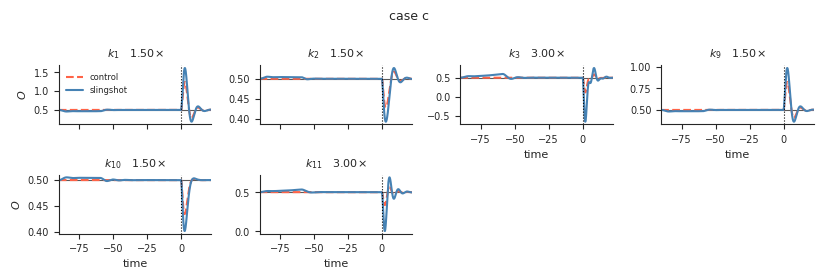

Figure saved to /home/amir/RL/autodiff-control/plots/SI_figure6_rpa_traces_d.pdf


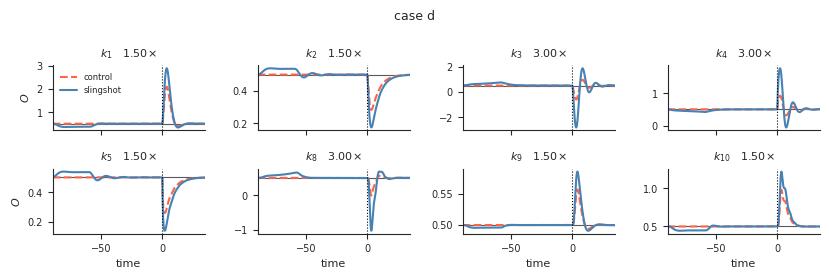

Figure saved to /home/amir/RL/autodiff-control/plots/SI_figure6_rpa_traces_e.pdf


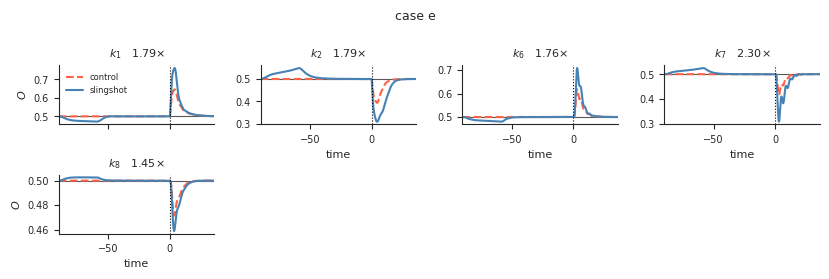

Figure saved to /home/amir/RL/autodiff-control/plots/SI_figure6_rpa_traces_f.pdf


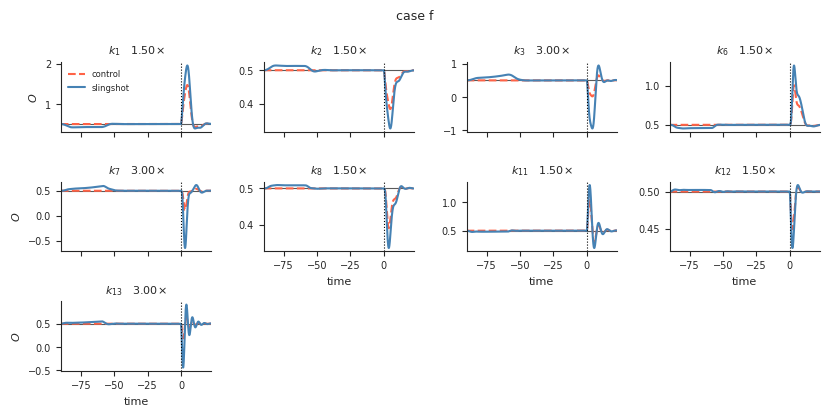

In [15]:
# --- SI: O(t) for every RPA parameter, one figure per network ---------------
N_COLS = 4
for m in MODELS:
    res = results[m.name]
    n = len(res)
    n_rows = int(np.ceil(n / N_COLS))
    t_max = 1.1 * max(r['t_settle'] for r in res.values())
    fig, axes = plt.subplots(n_rows, N_COLS, figsize=(2.1 * N_COLS, 1.4 * n_rows),
                             squeeze=False)
    for i, (ax, (p, r)) in enumerate(zip(axes.flat, res.items())):
        ax.plot(r['t'], r['O_ctrl'], **CTRL_STYLE)
        ax.plot(r['t'], r['O_sling'], **SLING_STYLE)
        ax.axhline(r['O_star'], color='0.35', lw=0.8, zorder=0)
        ax.axvline(0, color='k', ls=':', lw=0.8)
        ax.set_title(f"$k_{{{p[1:]}}}$   {r['A_peak']:.2f}×", fontsize=8)
        ax.set_xlim(-T_PREP, t_max)
        ax.tick_params(labelsize=7)
        if i + N_COLS < n:                   # a panel below: time axis lives there
            ax.tick_params(labelbottom=False)
        else:
            ax.set_xlabel('time', fontsize=8)
        clean_ax(ax)
    for ax in axes.flat[n:]:
        ax.set_visible(False)
    for ax in axes[:, 0]:
        ax.set_ylabel('$O$', fontsize=8)
    axes[0, 0].legend(frameon=False, fontsize=6)
    fig.suptitle(f'case {m.name}', fontsize=9)
    plt.tight_layout()
    save_fig(fig, f'SI_figure6_rpa_traces_{m.name}')
    plt.show()